# **DSK807: Applied Machine Learning**
## L05 Hands-on: Logistic Regression & Text Classification

This notebook has two main examples:

1. **Binary classification with numerical features**
   - Logistic Regression
   - train/test split and stratification
   - feature scaling
   - coefficients before and after scaling
   - probabilities, predictions, confusion matrix, accuracy, precision, recall, and F1

2. **Multiclass text classification**
   - CountVectorizer
   - TF–IDF
   - Logistic Regression
   - multiclass evaluation
   - comparison of vectorization methods

### Imports

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 43

# **Part 1: Binary Classification with Numerical Data**

We will use the **Breast Cancer Wisconsin dataset** included with scikit-learn.

The complete dataset contains 30 numerical features. To keep the example easy to inspect, we deliberately select only **five features**.

The target has two classes:

- `0` = malignant (Cancer)
- `1` = benign (No Cancer)

![Examples from the dataset.](https://miro.medium.com/v2/1*pxFCmhRFTighUn88baLcSA.png)

In [44]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer(as_frame=True)

df = data.frame.copy()

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


## **1.1 Select a small set of features**

In [45]:
features = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean smoothness",
    "mean concavity"
]

X = df[features]
y = df["target"]

print("Features:")
display(X.head())

print("\nClass distribution:")
print(y.value_counts().rename(index={0: "malignant", 1: "benign"}))

Features:


,mean radius,mean texture,mean perimeter,mean smoothness,mean concavity
0,17.99,10.38,122.80,0.11840,0.3001
1,20.57,17.77,132.90,0.08474,0.0869
2,19.69,21.25,130.00,0.10960,0.1974
3,11.42,20.38,77.58,0.14250,0.2414
4,20.29,14.34,135.10,0.10030,0.1980



Class distribution:
target
benign       357
malignant    212
Name: count, dtype: int64


### Look at the feature scales

Before fitting the model, inspect the ranges of the five features.

**Question:** Are all features measured on comparable scales?

In [46]:
X.describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
mean radius,14.127292,3.524049,6.98100,28.1100
mean texture,19.289649,4.301036,9.71000,39.2800
mean perimeter,91.969033,24.298981,43.79000,188.5000
mean smoothness,0.096360,0.014064,0.05263,0.1634
mean concavity,0.088799,0.079720,0.00000,0.4268


## **1.2 Train / test split**

We use `stratify=y` so that the class proportions are approximately preserved in both sets.

In [47]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTest class proportions:")
print(y_test.value_counts(normalize=True).sort_index())

Training samples: 426
Test samples: 143

Training class proportions:
target
0    0.373239
1    0.626761
Name: proportion, dtype: float64

Test class proportions:
target
0    0.370629
1    0.629371
Name: proportion, dtype: float64


## **1.3 Logistic Regression without scaling**

First, fit Logistic Regression using the original feature values.

We increase `max_iter` because optimization **can** require more iterations when features are on very different scales.

In [48]:
lr_raw = LogisticRegression(max_iter=5000) # default max_iter=100

lr_raw.fit(X_train, y_train)

y_pred_raw = lr_raw.predict(X_test)
y_prob_raw = lr_raw.predict_proba(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_raw))
print("F1 (binary):", f1_score(y_test, y_pred_raw))

Accuracy: 0.8811188811188811
F1 (binary): 0.9090909090909091


### **Inspect predicted probabilities**

In [49]:
probability_example = pd.DataFrame({
    "Actual": y_test.iloc[:10].values,
    "P(malignant)": y_prob_raw[:10, 0],
    "P(benign)": y_prob_raw[:10, 1],
    "Predicted": y_pred_raw[:10]
})

probability_example.round(3)

,Actual,P(malignant),P(benign),Predicted
0,1,0.001,0.999,1
1,1,0.017,0.983,1
2,0,0.844,0.156,0
3,1,0.040,0.960,1
4,0,0.840,0.160,0
5,1,0.034,0.966,1
6,1,0.159,0.841,1
7,1,0.153,0.847,1
8,1,0.795,0.205,0
9,1,0.003,0.997,1


### **Confusion matrix**

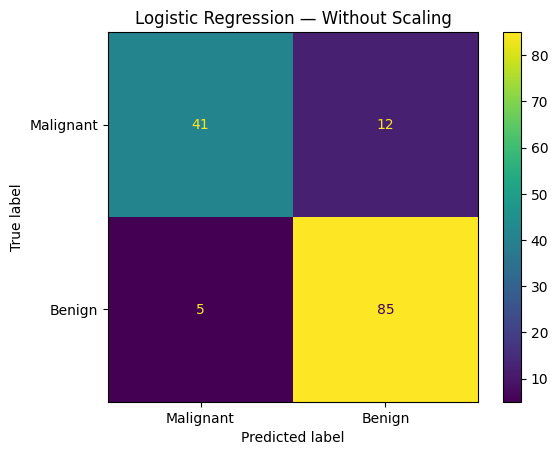

In [50]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_raw,
    display_labels=["Malignant", "Benign"]
)

plt.title("Logistic Regression — Without Scaling")
plt.show()

## **1.4 Scale the features**

`StandardScaler` transforms each feature approximately as:

$$
x' = \frac{x-\mu}{\sigma}
$$[link text]

After scaling, each training feature has approximately:

- mean = 0
- standard deviation = 1

**Important:** the scaler is fitted **only on the training data**.

In [51]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

scaled_summary = pd.DataFrame(
    X_train_scaled,
    columns=X.columns
).agg(["mean", "std"]).T

scaled_summary.round(3)

,mean,std
mean radius,-0.0,1.001
mean texture,-0.0,1.001
mean perimeter,-0.0,1.001
mean smoothness,0.0,1.001
mean concavity,0.0,1.001


### MinMax Scaling

In [52]:
from sklearn.preprocessing import MinMaxScaler

mmscaler = MinMaxScaler()

X_train_mmscaled = mmscaler.fit_transform(X_train)
X_test_mmscaled = mmscaler.transform(X_test)

mmscaled_summary = pd.DataFrame(
    X_train_mmscaled,
    columns=X.columns
).agg(["mean", "std"]).T

mmscaled_summary.round(3)

,mean,std
mean radius,0.354,0.178
mean texture,0.318,0.143
mean perimeter,0.350,0.179
mean smoothness,0.320,0.145
mean concavity,0.214,0.192


## **1.5 Logistic Regression after scaling**

In [53]:
## With Standarization (StandardScaler)
lr_scaled = LogisticRegression(max_iter=5000)

lr_scaled.fit(X_train_scaled, y_train)

y_pred_scaled = lr_scaled.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_scaled))
print("F1 (binary):", f1_score(y_test, y_pred_scaled))

Accuracy: 0.9090909090909091
F1 (binary): 0.9289617486338798


In [54]:
## With MinMax Scaling
lr_mmscaled = LogisticRegression(max_iter=5000)

lr_mmscaled.fit(X_train_mmscaled, y_train)

y_pred_mmscaled = lr_mmscaled.predict(X_test_mmscaled)

print("Accuracy:", accuracy_score(y_test, y_pred_mmscaled))
print("F1 (binary):", f1_score(y_test, y_pred_mmscaled))

Accuracy: 0.8881118881118881
F1 (binary): 0.9166666666666666


## **1.6 What happened to the coefficients?**

Remember:

$$
z = \beta_0+\beta_1x_1+\cdots+\beta_px_p
$$

A coefficient represents the change in the linear score associated with a **one-unit change in its feature**, holding the other features fixed.

When we change the units of the features through scaling, the numerical values of the coefficients also change.

In [55]:
coef_comparison = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient (original scale)": lr_raw.coef_[0],
    "Coefficient (standardized)": lr_scaled.coef_[0],
    "Coefficient (MinMaxScaled)": lr_mmscaled.coef_[0]
})

coef_comparison.round(4)

,Feature,Coefficient (original scale),Coefficient (standardized),Coefficient (MinMaxScaled)
0,mean radius,2.6643,-2.0520,-4.3103
1,mean texture,-0.2285,-1.3510,-2.6890
2,mean perimeter,-0.5651,-1.9902,-4.3774
3,mean smoothness,-0.3735,-1.2455,-2.1911
4,mean concavity,-1.2608,-1.4572,-3.9752


### Visual comparison of the coefficients

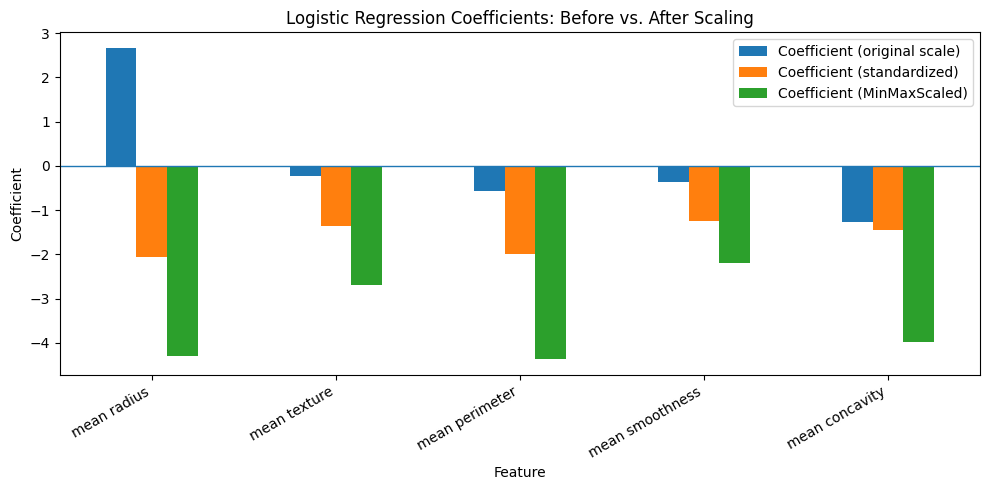

In [56]:
coef_plot = coef_comparison.set_index("Feature")

ax = coef_plot.plot(
    kind="bar",
    figsize=(10, 5)
)

ax.axhline(0, linewidth=1)
ax.set_ylabel("Coefficient")
ax.set_title("Logistic Regression Coefficients: Before vs. After Scaling")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## **1.7 Compare performance**

In [57]:
def binary_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred)
    }

comparison = pd.DataFrame({
    "Without scaling": binary_metrics(y_test, y_pred_raw),
    "With Standard scaling": binary_metrics(y_test, y_pred_scaled),
    "With MinMax scaling": binary_metrics(y_test, y_pred_mmscaled)
}).T

comparison.round(3)

,Accuracy,Precision,Recall,F1
Without scaling,0.881,0.876,0.944,0.909
With Standard scaling,0.909,0.914,0.944,0.929
With MinMax scaling,0.888,0.863,0.978,0.917


### Classification report

In [58]:
print(classification_report(
    y_test,
    y_pred_mmscaled,
    target_names=["Malignant", "Benign"]
))

              precision    recall  f1-score   support

   Malignant       0.95      0.74      0.83        53
      Benign       0.86      0.98      0.92        90

    accuracy                           0.89       143
   macro avg       0.91      0.86      0.87       143
weighted avg       0.90      0.89      0.88       143



## **1.8 The recommended workflow: use a Pipeline**

A pipeline ensures that the scaler is fitted on the training data and that exactly the same transformation is applied to new data.

In [59]:
numeric_model = Pipeline([
    ("scaler", MinMaxScaler()),
    ("logistic_regression", LogisticRegression(max_iter=5000))
])

numeric_model.fit(X_train, y_train)

y_pred_pipeline = numeric_model.predict(X_test)

print(classification_report(
    y_test,
    y_pred_pipeline,
    target_names=["Malignant", "Benign"]  # 這邊是重新貼標籤 腫瘤還是良性
))

              precision    recall  f1-score   support

   Malignant       0.95      0.74      0.83        53
      Benign       0.86      0.98      0.92        90

    accuracy                           0.89       143
   macro avg       0.91      0.86      0.87       143
weighted avg       0.90      0.89      0.88       143



---
# **Part 2: Multiclass Text Classification**

Now our input is **text**, but Logistic Regression requires numerical features.

We therefore need:

$$
\text{Text}
\rightarrow
\text{Vectorization}
\rightarrow
\text{Logistic Regression}
\rightarrow
\text{Class}
$$

We will use a subset of the **20 Newsgroups** dataset with four topics:

- `comp.graphics`
- `rec.sport.baseball`
- `sci.space`
- `talk.politics.misc`

This gives us a genuine **multiclass classification** problem.

In [60]:
from sklearn.datasets import fetch_20newsgroups

categories = [
    "comp.graphics",
    "rec.sport.baseball",
    "sci.space",
    "talk.politics.misc"
]

train_text = fetch_20newsgroups(
    subset="train",
    categories=categories,
    remove=("headers", "footers", "quotes"),
    random_state=RANDOM_STATE
)

test_text = fetch_20newsgroups(
    subset="test",
    categories=categories,
    remove=("headers", "footers", "quotes"),
    random_state=RANDOM_STATE
)

print("Training documents:", len(train_text.data))
print("Test documents:", len(test_text.data))
print("Classes:", train_text.target_names)

Training documents: 2239
Test documents: 1490
Classes: ['comp.graphics', 'rec.sport.baseball', 'sci.space', 'talk.politics.misc']


## **2.1 Inspect the raw text**

In [61]:
example_id = 20

print("CLASS:")
print(train_text.target_names[train_text.target[example_id]])

print("\nTEXT:")
print(train_text.data[example_id][:1200])

CLASS:
talk.politics.misc

TEXT:

	I don't believe in the "Wave Theory".


	My mother-in-law, who grew up in Germany, doesn't believe in 
money at all. She started out as a real estate developer, and now raises
horses. She keeps telling me that inflation is coming back, and to lock
in my fixed rate mortgage as low as possible.


	Maybe you'd like to invest in some foreign currency.

	Which one would you guess to come out on top ?

	(Sigh - speculators never learn.)



Bill R.

--


# **Example 2A — CountVectorizer**

`CountVectorizer` creates a **document-term matrix**.

Each column represents a vocabulary term and each cell contains the number of times that term occurs in a document.

For example:

| Document | space | baseball | image |
|---|---:|---:|---:|
| Document A | 3 | 0 | 1 |
| Document B | 0 | 4 | 0 |

Let's first use a tiny example so we can actually see the vectors.

In [62]:
from sklearn.feature_extraction.text import CountVectorizer

tiny_documents = [
    "space mission to mars",
    "mars mission launches spacecraft",
    "baseball team wins game"
]

tiny_count = CountVectorizer()
tiny_matrix = tiny_count.fit_transform(tiny_documents)

tiny_df = pd.DataFrame(
    tiny_matrix.toarray(),
    columns=tiny_count.get_feature_names_out()
)

tiny_df

,baseball,game,launches,mars,mission,space,spacecraft,team,to,wins
0,0,0,0,1,1,1,0,0,1,0
1,0,0,1,1,1,0,1,0,0,0
2,1,1,0,0,0,0,0,1,0,1


## 2.2 CountVectorizer + Logistic Regression

For the real dataset, we keep the representation sparse. We do **not** convert the full matrix to a dense array.

In [63]:
count_model = Pipeline([
    ("vectorizer", CountVectorizer(
        stop_words="english",
        min_df=2
    )),
    ("classifier", LogisticRegression(
        max_iter=2000
    ))
])

# stop_words="english"：去掉 the、is、and 這類常見但沒什麼意義的英文詞
# min_df=2：一個詞至少要出現在 2 份文件裡才會被收進詞彙表，只出現一次的詞（常是錯字或罕見詞）直接丟掉

count_model.fit(train_text.data, train_text.target)

count_pred = count_model.predict(test_text.data)

print(classification_report(
    test_text.target,
    count_pred,
    target_names=test_text.target_names
))

                    precision    recall  f1-score   support

     comp.graphics       0.89      0.87      0.88       389
rec.sport.baseball       0.77      0.91      0.83       397
         sci.space       0.81      0.76      0.79       394
talk.politics.misc       0.82      0.72      0.77       310

          accuracy                           0.82      1490
         macro avg       0.82      0.81      0.82      1490
      weighted avg       0.82      0.82      0.82      1490



### Confusion matrix: CountVectorizer

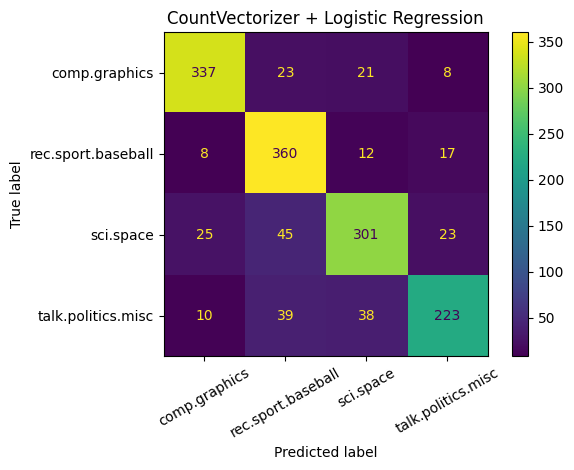

In [64]:
ConfusionMatrixDisplay.from_predictions(
    test_text.target,
    count_pred,
    display_labels=test_text.target_names,
    xticks_rotation=30
)

plt.title("CountVectorizer + Logistic Regression")
plt.tight_layout()
plt.show()

## 2.3 Inspect the vocabulary and matrix shape

In [65]:
count_vectorizer = count_model.named_steps["vectorizer"]

X_train_count = count_vectorizer.transform(train_text.data)

print("Document-term matrix shape:", X_train_count.shape)
print("Vocabulary size:", len(count_vectorizer.vocabulary_))
print("Matrix type:", type(X_train_count))

Document-term matrix shape: (2239, 12774)
Vocabulary size: 12774
Matrix type: <class 'scipy.sparse._csr.csr_matrix'>


# **Example 2B: TF–IDF**

Raw counts give frequent words large values.

TF–IDF gives more weight to terms that are important in a particular document but less common across the collection.

A common formulation is:

$$
\text{TF-IDF}(t,d)
=
\text{TF}(t,d)\times\text{IDF}(t)
$$

with

$$
\text{IDF}(t)
\approx
\log\left(\frac{N}{df(t)}\right)
$$

The exact implementation can include smoothing and normalization.

In [66]:
from sklearn.feature_extraction.text import TfidfVectorizer

tiny_tfidf = TfidfVectorizer()
tiny_tfidf_matrix = tiny_tfidf.fit_transform(tiny_documents)

tiny_tfidf_df = pd.DataFrame(
    tiny_tfidf_matrix.toarray(),
    columns=tiny_tfidf.get_feature_names_out()
)

tiny_tfidf_df.round(3)

,baseball,game,launches,mars,mission,space,spacecraft,team,to,wins
0,0.0,0.0,0.000,0.428,0.428,0.563,0.000,0.0,0.563,0.0
1,0.0,0.0,0.563,0.428,0.428,0.000,0.563,0.0,0.000,0.0
2,0.5,0.5,0.000,0.000,0.000,0.000,0.000,0.5,0.000,0.5


## 2.4 TF–IDF + Logistic Regression

In [67]:
tfidf_model = Pipeline([
    ("vectorizer", TfidfVectorizer(
        stop_words="english",
        min_df=2
    )),
    ("classifier", LogisticRegression(
        max_iter=2000
    ))
])

tfidf_model.fit(train_text.data, train_text.target)

tfidf_pred = tfidf_model.predict(test_text.data)

print(classification_report(
    test_text.target,
    tfidf_pred,
    target_names=test_text.target_names
))

                    precision    recall  f1-score   support

     comp.graphics       0.92      0.90      0.91       389
rec.sport.baseball       0.83      0.92      0.88       397
         sci.space       0.84      0.83      0.83       394
talk.politics.misc       0.89      0.80      0.84       310

          accuracy                           0.87      1490
         macro avg       0.87      0.86      0.86      1490
      weighted avg       0.87      0.87      0.86      1490



In [79]:
tfidf_model.predict_proba(test_text.data)

array([[0.5016364 , 0.11628178, 0.30209051, 0.07999132],
       [0.09882093, 0.08241173, 0.14297278, 0.67579456],
       [0.06541205, 0.7413787 , 0.08167492, 0.11153433],
       ...,
       [0.49863465, 0.12668906, 0.23745961, 0.13721668],
       [0.11131871, 0.67465465, 0.10856239, 0.10546424],
       [0.27535619, 0.20406413, 0.32826132, 0.19231836]], shape=(1490, 4))

### Confusion matrix: TF–IDF

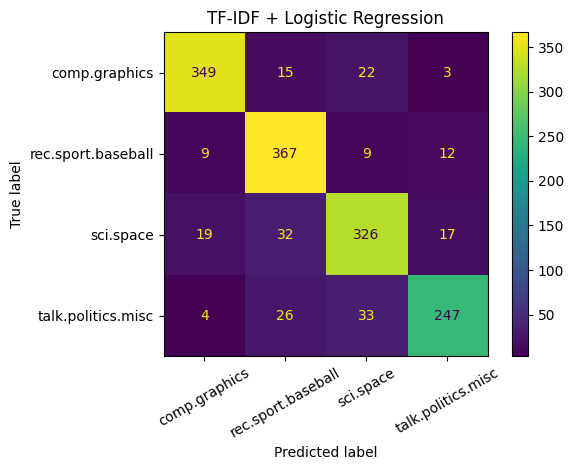

In [68]:
ConfusionMatrixDisplay.from_predictions(
    test_text.target,
    tfidf_pred,
    display_labels=test_text.target_names,
    xticks_rotation=30
)

plt.title("TF-IDF + Logistic Regression")
plt.tight_layout()
plt.show()

# 2.5 CountVectorizer vs. TF–IDF

In [69]:
def multiclass_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(y_true, y_pred, average="macro"),
        "Weighted F1": f1_score(y_true, y_pred, average="weighted"),
        "Micro F1": f1_score(y_true, y_pred, average="micro")
    }

text_results = pd.DataFrame({
    "CountVectorizer": multiclass_metrics(test_text.target, count_pred),
    "TF-IDF": multiclass_metrics(test_text.target, tfidf_pred)
}).T

text_results.round(3)

,Accuracy,Macro F1,Weighted F1,Micro F1
CountVectorizer,0.819,0.816,0.818,0.819
TF-IDF,0.865,0.863,0.865,0.865


## 2.6 What words does Logistic Regression associate with each class?

With CountVectorizer or TF–IDF, each input feature corresponds to a vocabulary term.

That makes the learned Logistic Regression coefficients particularly interesting to inspect.

In [70]:
vectorizer = tfidf_model.named_steps["vectorizer"]
classifier = tfidf_model.named_steps["classifier"]

feature_names = np.array(vectorizer.get_feature_names_out())

for class_id, class_name in enumerate(train_text.target_names):
    top_indices = np.argsort(classifier.coef_[class_id])[-10:][::-1]
    top_terms = feature_names[top_indices]

    print(f"\n{class_name}")
    print(", ".join(top_terms))


comp.graphics
graphics, image, file, files, 3d, computer, hi, windows, card, format

rec.sport.baseball
baseball, game, team, year, games, players, jewish, runs, hit, cubs

sci.space
space, nasa, orbit, moon, launch, spacecraft, earth, shuttle, lunar, solar

talk.politics.misc
people, clinton, government, tax, president, state, drugs, men, evidence, trial


## 2.7 Predict new text

In [71]:
new_documents = [
    "The spacecraft entered orbit and began transmitting data.",
    "The pitcher had an excellent game and the team scored in the final inning.",
    "The image rendering software supports three dimensional graphics."
]

predictions = tfidf_model.predict(new_documents)
probabilities = tfidf_model.predict_proba(new_documents)

for text, pred, probs in zip(new_documents, predictions, probabilities):
    print("\nTEXT:", text)
    print("PREDICTION:", train_text.target_names[pred])

    result = pd.Series(
        probs,
        index=train_text.target_names
    ).sort_values(ascending=False)

    display(result.round(3).to_frame("Probability"))


TEXT: The spacecraft entered orbit and began transmitting data.
PREDICTION: sci.space


,Probability
sci.space,0.711
rec.sport.baseball,0.116
comp.graphics,0.093
talk.politics.misc,0.081



TEXT: The pitcher had an excellent game and the team scored in the final inning.
PREDICTION: rec.sport.baseball


,Probability
rec.sport.baseball,0.877
sci.space,0.047
comp.graphics,0.044
talk.politics.misc,0.032



TEXT: The image rendering software supports three dimensional graphics.
PREDICTION: comp.graphics


,Probability
comp.graphics,0.887
sci.space,0.047
rec.sport.baseball,0.036
talk.politics.misc,0.029


---
# Optional Extension — Sentence Embeddings

**Skip this section if time is limited.**

CountVectorizer and TF–IDF represent documents using vocabulary-based sparse vectors.

A sentence embedding represents an entire text as a **dense numerical vector**:

$$
\text{Text}
\rightarrow
\text{Sentence Transformer}
\rightarrow
\text{Dense Vector}
\rightarrow
\text{Logistic Regression}
$$

Unlike bag-of-words representations, pretrained sentence embeddings can encode semantic information and similarities between texts.

The first cell installs `sentence-transformers` in Colab.

In [72]:
# Run only if you want to present the optional embedding example.
!pip -q install sentence-transformers

In [76]:
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

# Encoding the full dataset can take some time.
X_train_embeddings = embedding_model.encode(
    train_text.data,
    batch_size=64,
    show_progress_bar=True
)

X_test_embeddings = embedding_model.encode(
    test_text.data,
    batch_size=64,
    show_progress_bar=True
)

print("Training embedding shape:", X_train_embeddings.shape)
print("Test embedding shape:", X_test_embeddings.shape)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Batches:   0%|          | 0/35 [00:00<?, ?it/s]

Batches:   0%|          | 0/24 [00:00<?, ?it/s]

Training embedding shape: (2239, 384)
Test embedding shape: (1490, 384)


## Logistic Regression on sentence embeddings

In [74]:
embedding_classifier = LogisticRegression(max_iter=2000)

embedding_classifier.fit(
    X_train_embeddings,
    train_text.target
)

embedding_pred = embedding_classifier.predict(
    X_test_embeddings
)

print(classification_report(
    test_text.target,
    embedding_pred,
    target_names=test_text.target_names
))

                    precision    recall  f1-score   support

     comp.graphics       0.93      0.92      0.92       389
rec.sport.baseball       0.89      0.93      0.91       397
         sci.space       0.85      0.83      0.84       394
talk.politics.misc       0.86      0.85      0.86       310

          accuracy                           0.88      1490
         macro avg       0.88      0.88      0.88      1490
      weighted avg       0.88      0.88      0.88      1490



In [81]:
new_documents = [
    "The spacecraft entered orbit and began transmitting data.",
    "The pitcher had an excellent game and the team scored in the final inning.",
    "The image rendering software supports three dimensional graphics."
]

new_documents_embeddings = embedding_model.encode(
    new_documents,
    batch_size=64,
    show_progress_bar=True
)

predictions = embedding_classifier.predict(new_documents_embeddings)
probabilities = embedding_classifier.predict_proba(new_documents_embeddings)

for text, pred, probs in zip(new_documents, predictions, probabilities):
    print("\nTEXT:", text)
    print("PREDICTION:", train_text.target_names[pred])

    result = pd.Series(
        probs,
        index=train_text.target_names
    ).sort_values(ascending=False)

    display(result.round(3).to_frame("Probability"))

Batches:   0%|          | 0/1 [00:00<?, ?it/s]


TEXT: The spacecraft entered orbit and began transmitting data.
PREDICTION: sci.space


,Probability
sci.space,0.989
comp.graphics,0.009
rec.sport.baseball,0.001
talk.politics.misc,0.001



TEXT: The pitcher had an excellent game and the team scored in the final inning.
PREDICTION: rec.sport.baseball


,Probability
rec.sport.baseball,0.989
comp.graphics,0.004
sci.space,0.003
talk.politics.misc,0.003



TEXT: The image rendering software supports three dimensional graphics.
PREDICTION: comp.graphics


,Probability
comp.graphics,0.997
sci.space,0.002
rec.sport.baseball,0.001
talk.politics.misc,0.000


## Compare all representations

In [77]:
all_results = pd.DataFrame({
    "CountVectorizer": multiclass_metrics(test_text.target, count_pred),
    "TF-IDF": multiclass_metrics(test_text.target, tfidf_pred),
    "Sentence Transformer": multiclass_metrics(test_text.target, embedding_pred)
}).T

all_results.round(3)

,Accuracy,Macro F1,Weighted F1,Micro F1
CountVectorizer,0.819,0.816,0.818,0.819
TF-IDF,0.865,0.863,0.865,0.865
Sentence Transformer,0.884,0.882,0.884,0.884
